Dataset loaded successfully
Shape: (1000, 7)


,Attendance_Percentage,Previous_Grades,Assignment_Performance,Internal_Marks,Participation_Score,Backlog_Subjects,At_Risk
0,78.7,64.1,61.2,83.5,6.5,1,No
1,62.5,54.1,58.0,75.6,7.8,2,Yes
2,84.0,58.8,74.5,93.5,6.5,1,No
3,86.3,74.5,71.8,44.3,10.0,2,No
4,51.6,65.0,46.9,62.3,8.9,0,Yes



===== DATA TYPES =====
Attendance_Percentage     float64
Previous_Grades           float64
Assignment_Performance    float64
Internal_Marks            float64
Participation_Score       float64
Backlog_Subjects            int64
At_Risk                    object
dtype: object

===== MISSING VALUES =====
Attendance_Percentage     0
Previous_Grades           0
Assignment_Performance    0
Internal_Marks            0
Participation_Score       0
Backlog_Subjects          0
At_Risk                   0
dtype: int64

Total missing values: 0

Duplicate rows: 0

===== TARGET DISTRIBUTION =====
At_Risk
No     500
Yes    500
Name: count, dtype: int64

===== STATISTICAL SUMMARY =====


,count,mean,std,min,25%,50%,75%,max
Attendance_Percentage,1000.0,74.5997,11.678065,40.0,66.600,75.10,82.100,100.0
Previous_Grades,1000.0,63.8077,14.976432,30.0,54.075,64.35,74.000,100.0
Assignment_Performance,1000.0,68.4105,14.921332,30.0,58.100,68.55,78.900,100.0
Internal_Marks,1000.0,65.9322,13.542431,27.5,56.375,65.90,75.025,100.0
Participation_Score,1000.0,5.9467,1.936233,1.0,4.600,6.00,7.200,10.0
Backlog_Subjects,1000.0,1.1770,1.055834,0.0,0.000,1.00,2.000,5.0


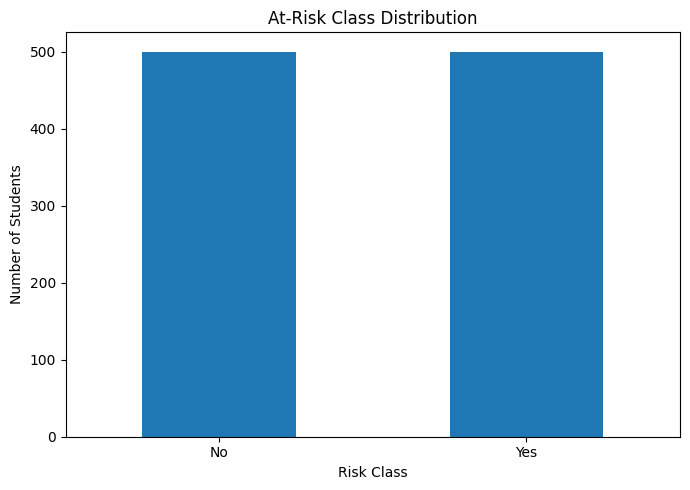

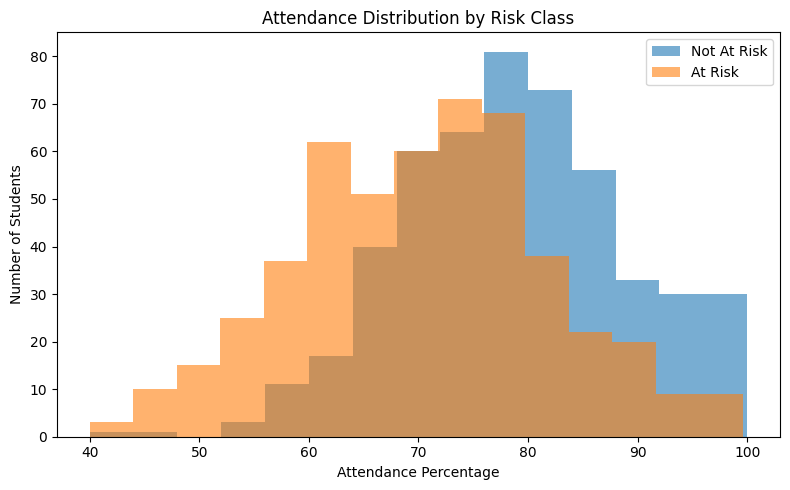

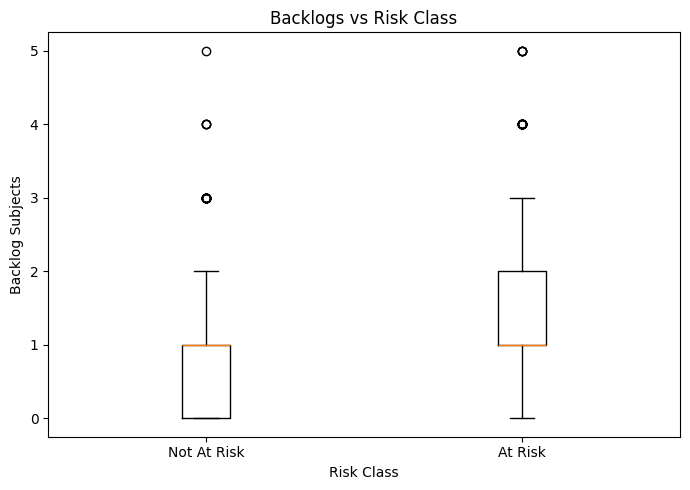

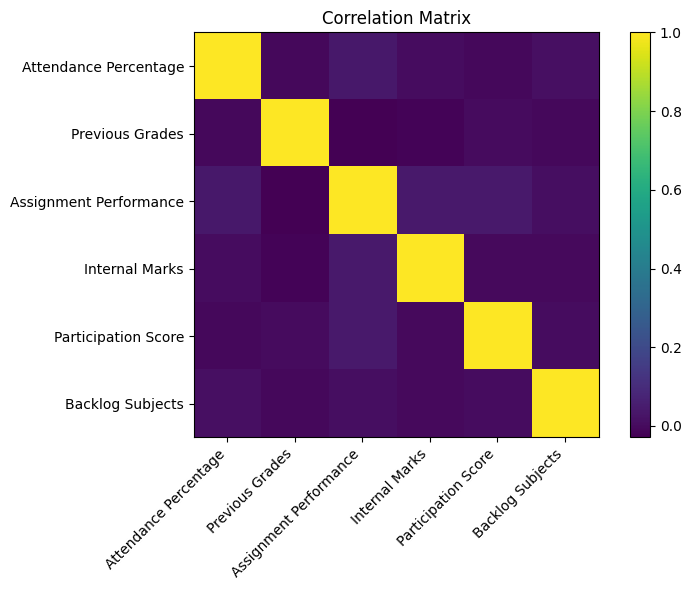


Target mapping:
No  -> 0
Yes -> 1

===== TRAIN / TEST =====
Training records: 800
Testing records: 200

===== STANDARD SCALER =====


,Feature,Training Mean,Training Std
0,Attendance_Percentage,74.862250,11.584727
1,Previous_Grades,63.721000,15.159473
2,Assignment_Performance,68.324125,15.081915
3,Internal_Marks,66.321375,13.647769
4,Participation_Score,5.881250,1.955153
5,Backlog_Subjects,1.173750,1.059982



Logistic Regression model trained.

===== LEARNED COEFFICIENTS =====


,Feature,Coefficient
0,Attendance_Percentage,-1.266244
1,Previous_Grades,-0.910538
2,Assignment_Performance,-0.655995
3,Internal_Marks,-0.900475
4,Participation_Score,-0.440025
5,Backlog_Subjects,1.345370


Intercept: 0.05145327966875087

===== PERFORMANCE =====
Accuracy  : 88.50%
Precision : 87.38%
Recall    : 90.00%
F1 Score  : 88.67%

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

 Not At Risk     0.8969    0.8700    0.8832       100
     At Risk     0.8738    0.9000    0.8867       100

    accuracy                         0.8850       200
   macro avg     0.8853    0.8850    0.8850       200
weighted avg     0.8853    0.8850    0.8850       200


===== CONFUSION MATRIX =====
[[87 13]
 [10 90]]

TN = 87
FP = 13
FN = 10
TP = 90


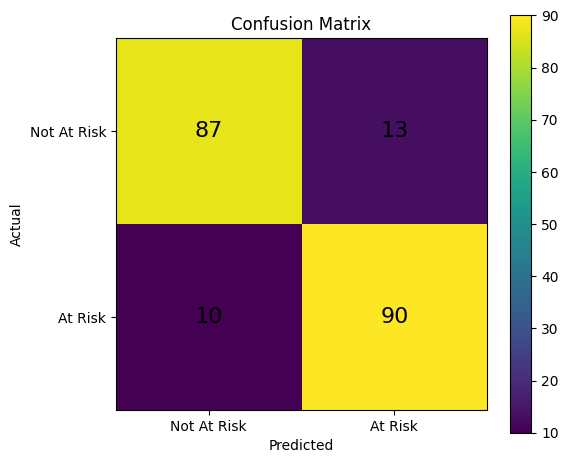


===== MANUAL CALCULATIONS =====
Accuracy = (90 + 87) / 200 = 88.50%
Precision = 90 / (90 + 13) = 87.38%
Recall = 90 / (90 + 10) = 90.00%
F1 Score = 88.67%

===== NEW STUDENT =====


,Attendance_Percentage,Previous_Grades,Assignment_Performance,Internal_Marks,Participation_Score,Backlog_Subjects
0,55,45,48,42,2,3



Standardized values:
[-1.7145 -1.2349 -1.3476 -1.7821 -1.9851  1.7229]

P(At Risk) = 99.99%
Prediction = YES (At Risk)

===== FULL CALCULATION =====

Training means and standard deviations:
Attendance_Percentage: Mean=74.86225, Std=11.58473
Previous_Grades: Mean=63.72100, Std=15.15947
Assignment_Performance: Mean=68.32413, Std=15.08191
Internal_Marks: Mean=66.32138, Std=13.64777
Participation_Score: Mean=5.88125, Std=1.95515
Backlog_Subjects: Mean=1.17375, Std=1.05998

Standardization:
Attendance_Percentage: (55 - 74.86225) / 11.58473 = -1.7145
Previous_Grades: (45 - 63.72100) / 15.15947 = -1.2349
Assignment_Performance: (48 - 68.32413) / 15.08191 = -1.3476
Internal_Marks: (42 - 66.32138) / 13.64777 = -1.7821
Participation_Score: (2 - 5.88125) / 1.95515 = -1.9851
Backlog_Subjects: (3 - 1.17375) / 1.05998 = 1.7229

Coefficients:
Attendance_Percentage = -1.26624
Previous_Grades = -0.91054
Assignment_Performance = -0.65599
Internal_Marks = -0.90048
Participation_Score = -0.44002
Backlog_

In [1]:
# ============================================================
# STUDENT ACADEMIC RISK PREDICTION SYSTEM
# ============================================================

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. LOAD DATASET
# ============================================================

df = pd.read_csv("/content/Student_Academic_Risk_Dataset.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

display(df.head())

# ============================================================
# 2. DEFINE FEATURES AND TARGET
# ============================================================

features = [
    "Attendance_Percentage",
    "Previous_Grades",
    "Assignment_Performance",
    "Internal_Marks",
    "Participation_Score",
    "Backlog_Subjects"
]

target = "At_Risk"

# ============================================================
# 3. DATA INSPECTION
# ============================================================

print("\n===== DATA TYPES =====")
print(df.dtypes)

print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

print("\nTotal missing values:",
      df.isnull().sum().sum())

print("\nDuplicate rows:",
      df.duplicated().sum())

print("\n===== TARGET DISTRIBUTION =====")
print(df[target].value_counts())

print("\n===== STATISTICAL SUMMARY =====")
display(df[features].describe().T)

# ============================================================
# 4. EDA
# ============================================================

os.makedirs("/content/eda_images", exist_ok=True)

# ---------------- TARGET DISTRIBUTION ----------------

plt.figure(figsize=(7,5))

df[target].value_counts().plot(kind="bar")

plt.title("At-Risk Class Distribution")
plt.xlabel("Risk Class")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "/content/eda_images/01_target_distribution.png",
    dpi=200
)

plt.show()

# ---------------- ATTENDANCE DISTRIBUTION ----------------

plt.figure(figsize=(8,5))

for label in ["No", "Yes"]:

    values = df.loc[
        df[target] == label,
        "Attendance_Percentage"
    ]

    plt.hist(
        values,
        bins=15,
        alpha=0.6,
        label=label
    )

plt.title("Attendance Distribution by Risk Class")
plt.xlabel("Attendance Percentage")
plt.ylabel("Number of Students")

plt.legend(["Not At Risk", "At Risk"])

plt.tight_layout()

plt.savefig(
    "/content/eda_images/02_attendance_distribution.png",
    dpi=200
)

plt.show()

# ---------------- BACKLOG BOX PLOT ----------------

plt.figure(figsize=(7,5))

not_risk = df.loc[
    df[target] == "No",
    "Backlog_Subjects"
]

risk = df.loc[
    df[target] == "Yes",
    "Backlog_Subjects"
]

plt.boxplot(
    [not_risk, risk],
    tick_labels=["Not At Risk", "At Risk"]
)

plt.title("Backlogs vs Risk Class")
plt.xlabel("Risk Class")
plt.ylabel("Backlog Subjects")

plt.tight_layout()

plt.savefig(
    "/content/eda_images/03_backlogs_vs_risk.png",
    dpi=200
)

plt.show()

# ---------------- CORRELATION MATRIX ----------------

correlation = df[features].corr()

plt.figure(figsize=(8,6))

plt.imshow(
    correlation,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(features)),
    [f.replace("_"," ") for f in features],
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(features)),
    [f.replace("_"," ") for f in features]
)

plt.title("Correlation Matrix")

plt.tight_layout()

plt.savefig(
    "/content/eda_images/04_correlation_matrix.png",
    dpi=200
)

plt.show()

# ============================================================
# 5. PREPARE X AND y
# ============================================================

X = df[features]

y = df[target].map({
    "No": 0,
    "Yes": 1
})

print("\nTarget mapping:")
print("No  -> 0")
print("Yes -> 1")

# ============================================================
# 6. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("\n===== TRAIN / TEST =====")

print("Training records:",
      len(X_train))

print("Testing records:",
      len(X_test))

# ============================================================
# 7. STANDARD SCALER
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("\n===== STANDARD SCALER =====")

scaler_table = pd.DataFrame({

    "Feature": features,

    "Training Mean": scaler.mean_,

    "Training Std": scaler.scale_

})

display(scaler_table)

# ============================================================
# 8. TRAIN LOGISTIC REGRESSION MODEL
# ============================================================

model = LogisticRegression(
    random_state=42
)

model.fit(
    X_train_scaled,
    y_train
)

print("\nLogistic Regression model trained.")

# ============================================================
# 9. LEARNED COEFFICIENTS
# ============================================================

coefficients = pd.DataFrame({

    "Feature": features,

    "Coefficient": model.coef_[0]

})

print("\n===== LEARNED COEFFICIENTS =====")

display(coefficients)

print(
    "Intercept:",
    model.intercept_[0]
)

# ============================================================
# 10. TEST PREDICTIONS
# ============================================================

y_pred = model.predict(
    X_test_scaled
)

y_probability = model.predict_proba(
    X_test_scaled
)[:,1]

# ============================================================
# 11. PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

print("\n===== PERFORMANCE =====")

print(
    f"Accuracy  : {accuracy*100:.2f}%"
)

print(
    f"Precision : {precision*100:.2f}%"
)

print(
    f"Recall    : {recall*100:.2f}%"
)

print(
    f"F1 Score  : {f1*100:.2f}%"
)

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Not At Risk",
            "At Risk"
        ],
        digits=4
    )
)

# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\n===== CONFUSION MATRIX =====")

print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTN =", tn)
print("FP =", fp)
print("FN =", fn)
print("TP =", tp)

plt.figure(figsize=(6,5))

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title("Confusion Matrix")

plt.colorbar()

plt.xticks(
    [0,1],
    ["Not At Risk","At Risk"]
)

plt.yticks(
    [0,1],
    ["Not At Risk","At Risk"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm[i,j],
            ha="center",
            va="center",
            fontsize=16
        )

plt.tight_layout()

plt.savefig(
    "/content/eda_images/05_confusion_matrix.png",
    dpi=200
)

plt.show()

# ============================================================
# 13. MANUAL METRIC CALCULATIONS
# ============================================================

total = (
    tp +
    tn +
    fp +
    fn
)

accuracy_manual = (
    tp + tn
) / total

precision_manual = (
    tp
) / (
    tp + fp
)

recall_manual = (
    tp
) / (
    tp + fn
)

f1_manual = (
    2 *
    precision_manual *
    recall_manual
) / (
    precision_manual +
    recall_manual
)

print("\n===== MANUAL CALCULATIONS =====")

print(
    f"Accuracy = "
    f"({tp} + {tn}) / {total} "
    f"= {accuracy_manual*100:.2f}%"
)

print(
    f"Precision = "
    f"{tp} / ({tp} + {fp}) "
    f"= {precision_manual*100:.2f}%"
)

print(
    f"Recall = "
    f"{tp} / ({tp} + {fn}) "
    f"= {recall_manual*100:.2f}%"
)

print(
    f"F1 Score = "
    f"{f1_manual*100:.2f}%"
)

# ============================================================
# 14. NEW STUDENT PREDICTION
# ============================================================

example_student = pd.DataFrame({

    "Attendance_Percentage": [55],

    "Previous_Grades": [45],

    "Assignment_Performance": [48],

    "Internal_Marks": [42],

    "Participation_Score": [2],

    "Backlog_Subjects": [3]

})

example_scaled = scaler.transform(
    example_student[features]
)

probability = model.predict_proba(
    example_scaled
)[0,1]

prediction = model.predict(
    example_scaled
)[0]

print("\n===== NEW STUDENT =====")

display(example_student)

print("\nStandardized values:")

print(
    np.round(
        example_scaled[0],
        4
    )
)

print(
    f"\nP(At Risk) = "
    f"{probability*100:.2f}%"
)

print(
    "Prediction =",
    "YES (At Risk)"
    if prediction == 1
    else
    "NO (Not At Risk)"
)

# ============================================================
# 15. FULL MATHEMATICAL CALCULATION
# ============================================================

z = (

    model.intercept_[0]

    +

    np.dot(
        model.coef_[0],
        example_scaled[0]
    )

)

sigmoid_probability = (
    1 /
    (
        1 +
        np.exp(-z)
    )
)

print("\n===== FULL CALCULATION =====")

print("\nTraining means and standard deviations:")

for feature, mean, std in zip(
    features,
    scaler.mean_,
    scaler.scale_
):

    print(
        f"{feature}: "
        f"Mean={mean:.5f}, "
        f"Std={std:.5f}"
    )

print("\nStandardization:")

for feature, raw, mean, std, standardized in zip(

    features,

    example_student[
        features
    ].iloc[0],

    scaler.mean_,

    scaler.scale_,

    example_scaled[0]

):

    print(

        f"{feature}: "

        f"({raw} - {mean:.5f}) / "

        f"{std:.5f} = "

        f"{standardized:.4f}"

    )

print("\nCoefficients:")

for feature, coefficient in zip(
    features,
    model.coef_[0]
):

    print(
        feature,
        "=",
        round(coefficient,5)
    )

print(
    "\nIntercept =",
    round(
        model.intercept_[0],
        5
    )
)

print(
    f"\nz = {z:.4f}"
)

print(
    f"P(At Risk) = "
    f"1 / (1 + e^(-{z:.4f}))"
)

print(
    f"P(At Risk) = "
    f"{sigmoid_probability:.6f}"
)

print(
    f"P(At Risk) = "
    f"{sigmoid_probability*100:.2f}%"
)

print("\nDecision:")

if sigmoid_probability >= 0.50:

    print(
        "Probability >= 0.50"
    )

    print(
        "Prediction = YES (At Risk)"
    )

else:

    print(
        "Probability < 0.50"
    )

    print(
        "Prediction = NO (Not At Risk)"
    )

# ============================================================
# 16. SAVE MODEL AND SCALER
# ============================================================

with open(
    "/content/student_risk_logistic_regression.pkl",
    "wb"
) as f:

    pickle.dump(
        model,
        f
    )

with open(
    "/content/student_risk_scaler.pkl",
    "wb"
) as f:

    pickle.dump(
        scaler,
        f
    )

print("\nModel saved:")
print(
    "/content/student_risk_logistic_regression.pkl"
)

print(
    "/content/student_risk_scaler.pkl"
)

# ============================================================
# PROJECT SUMMARY
# ============================================================

print("\n===================================")
print("PROJECT SUMMARY")
print("===================================")

print(
    "Learning Type: Supervised Learning"
)

print(
    "Problem: Binary Classification"
)

print(
    "Algorithm: Logistic Regression"
)

print(
    "Preprocessing: StandardScaler"
)

print(
    "Training Records: 800"
)

print(
    "Testing Records: 200"
)

print(
    f"Accuracy: {accuracy*100:.2f}%"
)

print(
    f"Precision: {precision*100:.2f}%"
)

print(
    f"Recall: {recall*100:.2f}%"
)

print(
    f"F1 Score: {f1*100:.2f}%"
)

print(
    f"Example P(At Risk): "
    f"{probability*100:.2f}%"
)

print(
    "Example Prediction:",
    "YES"
    if prediction == 1
    else
    "NO"
)